# V2 Model Optimization Experiment

This notebook tests whether constrained models generalize better than the saved V1 random forests. It is an isolated experiment: V1 models, metrics, notebooks, prediction services, and dashboard files are read-only.

The final test period is reserved for one evaluation of V1 and the selected V2 models after validation-based selection. No test result is used to select a configuration or threshold.

## 1. Project objective and existing diagnostics

The V1 regression forest has validation/test MAE near 6.26 minutes, compared with training MAE near 3.31. The V1 classifier has near-perfect training ROC-AUC/PR-AUC (about 0.998/0.995), versus approximately 0.779/0.582 on validation. The saved classification threshold is 0.29 and was selected using validation data.

This experiment will test constrained forests plus regularized/boosting baselines. Candidate selection uses validation MAE for regression and validation PR-AUC for classification; training metrics and generalization gaps remain visible. A V2 model is preferred only when it improves the primary validation metric and reduces its corresponding train-validation gap.

These are observed V1 results. Explanations for the gaps are hypotheses unless directly measured below.

## 2. Dataset loading and validation

Use the six approved order-placement inputs and existing targets. Weather and traffic remain excluded because their availability at prediction time was not verified. The Module 02 report treats `distance_km` as a placement-time candidate only if the selected store and customer coordinates are known before prediction; verify this workflow assumption before deployment.

The 30-minute late definition is analytical, not an official customer promise.

In [1]:
from __future__ import annotations

import json
import sys
import time
import warnings
from pathlib import Path

import joblib
from joblib import parallel_backend
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import (
    HistGradientBoostingClassifier,
    HistGradientBoostingRegressor,
    RandomForestClassifier,
    RandomForestRegressor,
)
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    precision_score,
    r2_score,
    recall_score,
    roc_auc_score,
    RocCurveDisplay,
    PrecisionRecallDisplay,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

ROOT = Path.cwd().resolve()
if not (ROOT / "data" / "model_ready_data.csv").is_file():
    ROOT = ROOT.parent
if not (ROOT / "data" / "model_ready_data.csv").is_file():
    raise FileNotFoundError("Run this notebook from the project or notebooks directory.")
sys.path.insert(0, str(ROOT))

from src.feature_engineering import (
    CATEGORICAL_FEATURES,
    ENGINEERED_NUMERIC_FEATURES,
    FEATURES,
    engineer_features,
)

warnings.filterwarnings("ignore", category=FutureWarning)
RANDOM_STATE = 42
SLA_MINUTES = 30
ROOT = Path.cwd().resolve()
if not (ROOT / "data" / "model_ready_data.csv").is_file():
    ROOT = ROOT.parent
if not (ROOT / "data" / "model_ready_data.csv").is_file():
    raise FileNotFoundError("Run this notebook from the project or notebooks directory.")

DATA_PATH = ROOT / "data" / "model_ready_data.csv"
MODEL_DIR = ROOT / "models"
EXPERIMENT_MODEL_DIR = MODEL_DIR / "experimental"
OUTPUT_DIR = ROOT / "outputs" / "model_optimization"
REG_PLOT_DIR = OUTPUT_DIR / "regression_plots"
CLF_PLOT_DIR = OUTPUT_DIR / "classification_plots"
for folder in (EXPERIMENT_MODEL_DIR, REG_PLOT_DIR, CLF_PLOT_DIR):
    folder.mkdir(parents=True, exist_ok=True)

REG_TARGET = "delivery_time"
CLF_TARGET = "is_late"
EXPECTED_FEATURES = [
    "Order_Date", "Time_Orderd", "Type_of_order", "City", "Festival", "distance_km"
]
assert FEATURES == EXPECTED_FEATURES

with (MODEL_DIR / "model_metadata.json").open(encoding="utf-8") as file:
    v1_metadata = json.load(file)
with (MODEL_DIR / "classification_threshold.json").open(encoding="utf-8") as file:
    v1_threshold_data = json.load(file)
with (ROOT / "outputs" / "ml" / "regression_metrics.json").open(encoding="utf-8") as file:
    v1_reg_saved = json.load(file)
with (ROOT / "outputs" / "ml" / "classification_metrics.json").open(encoding="utf-8") as file:
    v1_clf_saved = json.load(file)

if v1_metadata["approved_raw_features"] != FEATURES:
    raise AssertionError("V1 metadata does not match the approved input feature list.")
if int(v1_metadata["sla_minutes"]) != SLA_MINUTES:
    raise AssertionError("V1 metadata does not use the expected 30-minute analytical SLA.")
V1_THRESHOLD = float(v1_threshold_data["threshold"])
if not np.isclose(V1_THRESHOLD, 0.29):
    raise AssertionError(f"Unexpected V1 threshold: {V1_THRESHOLD}")

data = pd.read_csv(DATA_PATH)
required = set(FEATURES + [REG_TARGET, CLF_TARGET, "ID"])
missing_columns = sorted(required - set(data.columns))
if missing_columns:
    raise KeyError(f"Model-ready dataset is missing columns: {missing_columns}")
if data["ID"].astype("string").str.strip().duplicated().any():
    raise AssertionError("Order IDs must be unique for split validation.")

v1_regression = joblib.load(MODEL_DIR / "regression_pipeline.joblib")
v1_classification = joblib.load(MODEL_DIR / "classification_pipeline.joblib")

print(f"Dataset rows: {len(data):,}")
print("Approved raw features:", FEATURES)
print("V1 regression:", type(v1_regression.named_steps["model"]).__name__)
print("V1 classification:", type(v1_classification.named_steps["model"]).__name__)
print("Saved V1 classification threshold:", V1_THRESHOLD)
display(data[FEATURES + [REG_TARGET, CLF_TARGET]].head())

Dataset rows: 45,593
Approved raw features: ['Order_Date', 'Time_Orderd', 'Type_of_order', 'City', 'Festival', 'distance_km']
V1 regression: RandomForestRegressor
V1 classification: RandomForestClassifier
Saved V1 classification threshold: 0.29


,Order_Date,Time_Orderd,Type_of_order,City,Festival,distance_km,delivery_time,is_late
0,2022-03-19,11:30:00,Snack,Urban,No,3.025153,24,0
1,2022-03-25,19:45:00,Snack,Metropolitan,No,20.183558,33,1
2,2022-03-19,08:30:00,Drinks,Urban,No,1.552760,26,0
3,2022-04-05,18:00:00,Buffet,Metropolitan,No,7.790412,21,0
4,2022-03-26,13:30:00,Snack,Metropolitan,No,6.210147,30,0


## 3. Recreate and verify chronological splits

The source notebook partitions unique normalized order dates in chronological order using 70%/15%/15%. This reproduces the saved boundaries and row counts. Every date and order remains in one partition only.

In [2]:
target_reg = pd.to_numeric(data[REG_TARGET], errors="coerce")
target_clf = pd.to_numeric(data[CLF_TARGET], errors="coerce")
eligible = target_reg.notna() & target_clf.notna()
X = data.loc[eligible, FEATURES].copy()
y_reg = target_reg.loc[eligible].astype(float)
y_clf = target_clf.loc[eligible].astype("int8")

if not y_clf.equals((y_reg > SLA_MINUTES).astype("int8").rename(CLF_TARGET)):
    raise AssertionError("is_late does not match delivery_time > 30 minutes.")
if not y_clf.isin([0, 1]).all():
    raise AssertionError("Classification target must contain only 0 and 1.")

dates = pd.to_datetime(X["Order_Date"], errors="coerce").dt.normalize()
if dates.isna().any():
    raise ValueError("Chronological evaluation cannot include rows without a valid order date.")
unique_dates = np.sort(dates.unique())
train_end = max(1, int(np.floor(len(unique_dates) * 0.70)))
validation_end = max(train_end + 1, int(np.floor(len(unique_dates) * 0.85)))
validation_end = min(validation_end, len(unique_dates) - 1)
partition_masks = {
    "train": dates.isin(unique_dates[:train_end]),
    "validation": dates.isin(unique_dates[train_end:validation_end]),
    "test": dates.isin(unique_dates[validation_end:]),
}

split_rows = []
partition_ids = {}
for name, mask in partition_masks.items():
    part_dates = dates.loc[mask]
    ids = set(data.loc[eligible, "ID"].loc[mask].astype("string"))
    partition_ids[name] = ids
    expected = v1_metadata["date_split"][name]
    first_date = str(part_dates.min().date())
    last_date = str(part_dates.max().date())
    if len(part_dates) != int(expected["rows"]):
        raise AssertionError(f"{name} row count differs from the saved V1 split.")
    if first_date != expected["first_date"] or last_date != expected["last_date"]:
        raise AssertionError(f"{name} date range differs from the saved V1 split.")
    split_rows.append({
        "partition": name, "rows": int(mask.sum()),
        "first_date": first_date, "last_date": last_date,
        "late_rate": float(y_clf.loc[mask].mean()),
    })

assert partition_ids["train"].isdisjoint(partition_ids["validation"])
assert partition_ids["train"].isdisjoint(partition_ids["test"])
assert partition_ids["validation"].isdisjoint(partition_ids["test"])
split_table = pd.DataFrame(split_rows)
display(split_table)

X_train, X_validation, X_test = (
    X.loc[partition_masks[name]] for name in ("train", "validation", "test")
)
y_reg_train, y_reg_validation, y_reg_test = (
    y_reg.loc[partition_masks[name]] for name in ("train", "validation", "test")
)
y_clf_train, y_clf_validation, y_clf_test = (
    y_clf.loc[partition_masks[name]] for name in ("train", "validation", "test")
)

print("Chronological split assertions passed; V1 model files remain read-only.")

,partition,rows,first_date,last_date,late_rate
0,train,30739,2022-02-11,2022-03-23,0.301018
1,validation,7525,2022-03-24,2022-03-30,0.280664
2,test,7329,2022-03-31,2022-04-06,0.305772


Chronological split assertions passed; V1 model files remain read-only.


## 4. Train-fitted preprocessing and V1 baselines

Date/time features reuse the existing feature-engineering function. Median imputation and category encoding are fitted using training data only. Reusing the same fitted transformer for all candidates keeps the grid practical and avoids validation/test leakage.

In [3]:
def make_preprocessor():
    numeric = Pipeline([("imputer", SimpleImputer(strategy="median"))])
    categorical = Pipeline([
        ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ])
    return ColumnTransformer(
        [
            ("numeric", numeric, ENGINEERED_NUMERIC_FEATURES),
            ("categorical", categorical, CATEGORICAL_FEATURES),
        ],
        remainder="drop",
        sparse_threshold=0,
    )


engineered_train = engineer_features(X_train)
engineered_validation = engineer_features(X_validation)
engineered_test = engineer_features(X_test)
preprocessor = make_preprocessor()
Z_train = preprocessor.fit_transform(engineered_train)
Z_validation = preprocessor.transform(engineered_validation)
Z_test = preprocessor.transform(engineered_test)
if Z_train.shape[1] != Z_validation.shape[1] or Z_train.shape[1] != Z_test.shape[1]:
    raise AssertionError("Transformed feature dimensions differ between partitions.")
print("Train-fitted transformed matrix:", Z_train.shape)


def regression_metrics(y_true, prediction):
    return {
        "mae": float(mean_absolute_error(y_true, prediction)),
        "rmse": float(np.sqrt(mean_squared_error(y_true, prediction))),
        "r2": float(r2_score(y_true, prediction)),
    }


def classification_metrics(y_true, scores, threshold=0.5):
    predicted = (np.asarray(scores) >= threshold).astype("int8")
    tn, fp, fn, tp = confusion_matrix(y_true, predicted, labels=[0, 1]).ravel()
    return {
        "threshold": float(threshold),
        "roc_auc": float(roc_auc_score(y_true, scores)),
        "pr_auc": float(average_precision_score(y_true, scores)),
        "precision": float(precision_score(y_true, predicted, zero_division=0)),
        "recall": float(recall_score(y_true, predicted, zero_division=0)),
        "f1": float(f1_score(y_true, predicted, zero_division=0)),
        "accuracy": float(accuracy_score(y_true, predicted)),
        "balanced_accuracy": float(balanced_accuracy_score(y_true, predicted)),
        "confusion_matrix": [[int(tn), int(fp)], [int(fn), int(tp)]],
    }


def predict_regression(pipeline, X_part):
    with parallel_backend("threading"):
        return pipeline.predict(X_part)


def predict_late_scores(pipeline, X_part):
    with parallel_backend("threading"):
        return pipeline.predict_proba(X_part)[:, 1]


def v1_regression_metrics(X_part, y_part):
    return regression_metrics(y_part, predict_regression(v1_regression, X_part))


def v1_classification_metrics(X_part, y_part, threshold):
    score = predict_late_scores(v1_classification, X_part)
    return classification_metrics(y_part, score, threshold)


v1_reg_train_metrics = v1_regression_metrics(X_train, y_reg_train)
v1_reg_validation_metrics = v1_regression_metrics(X_validation, y_reg_validation)
v1_clf_train_scores = predict_late_scores(v1_classification, X_train)
v1_clf_validation_scores = predict_late_scores(v1_classification, X_validation)
v1_clf_train_metrics = classification_metrics(y_clf_train, v1_clf_train_scores, 0.5)
v1_clf_validation_metrics = classification_metrics(
    y_clf_validation, v1_clf_validation_scores, 0.5
)

for metric in ("mae", "rmse", "r2"):
    if not np.isclose(v1_reg_validation_metrics[metric], v1_reg_saved["validation"][metric], atol=1e-10):
        raise AssertionError(f"Recomputed V1 validation {metric} differs from saved result.")
for metric in ("roc_auc", "pr_auc"):
    if not np.isclose(
        v1_clf_validation_metrics[metric],
        v1_clf_saved["threshold_selection"]["validation_at_0_5"][metric],
        atol=1e-10,
    ):
        raise AssertionError(f"Recomputed V1 validation {metric} differs from saved result.")
print("V1 train/validation metrics recomputed; validation metrics match saved V1 results.")

Train-fitted transformed matrix: (30739, 23)


V1 train/validation metrics recomputed; validation metrics match saved V1 results.


## 5. Regression experiments

The Random Forest grid tests 18 combinations: depth 8/12/16, leaf size 5/10/15, and `max_features` 0.6/0.8, with 200 trees. Ridge and histogram gradient boosting provide different regularized/boosting comparisons. The candidate ranking uses validation MAE only; train-validation MAE gaps are diagnostic, not a way to reward training fit.

In [4]:
regression_candidates = []
regression_estimators = {}
regression_train_predictions = {}
regression_validation_predictions = {}


def register_regression(name, estimator):
    started = time.perf_counter()
    with parallel_backend("threading", n_jobs=4):
        estimator.fit(Z_train, y_reg_train)
        train_prediction = estimator.predict(Z_train)
        validation_prediction = estimator.predict(Z_validation)
    train_metrics = regression_metrics(y_reg_train, train_prediction)
    validation_metrics = regression_metrics(y_reg_validation, validation_prediction)
    validation_residuals = y_reg_validation.to_numpy() - validation_prediction
    row = {
        "model": name,
        **{f"train_{key}": value for key, value in train_metrics.items()},
        **{f"validation_{key}": value for key, value in validation_metrics.items()},
        "train_validation_mae_gap": validation_metrics["mae"] - train_metrics["mae"],
        "train_validation_rmse_gap": validation_metrics["rmse"] - train_metrics["rmse"],
        "validation_residual_mean": float(np.mean(validation_residuals)),
        "validation_residual_std": float(np.std(validation_residuals, ddof=1)),
        "validation_residual_p05": float(np.quantile(validation_residuals, 0.05)),
        "validation_residual_median": float(np.median(validation_residuals)),
        "validation_residual_p95": float(np.quantile(validation_residuals, 0.95)),
        "fit_seconds": round(time.perf_counter() - started, 2),
    }
    regression_candidates.append(row)
    regression_estimators[name] = estimator
    regression_train_predictions[name] = train_prediction
    regression_validation_predictions[name] = validation_prediction


regression_grid = [
    (depth, leaf, features)
    for depth in (8, 12, 16)
    for leaf in (5, 10, 15)
    for features in (0.6, 0.8)
]
for depth, leaf, features in regression_grid:
    name = f"RandomForest_d{depth}_leaf{leaf}_features{features}"
    register_regression(
        name,
        RandomForestRegressor(
            n_estimators=200, max_depth=depth, min_samples_leaf=leaf,
            max_features=features, n_jobs=4, random_state=RANDOM_STATE,
        ),
    )

register_regression("Ridge_scaled_alpha2", Pipeline([
    ("scaler", StandardScaler()),
    ("model", Ridge(alpha=2.0)),
]))
register_regression("HistGradientBoosting", HistGradientBoostingRegressor(
    max_iter=150, max_leaf_nodes=15, l2_regularization=1.0,
    learning_rate=0.08, random_state=RANDOM_STATE,
))

regression_comparison = pd.DataFrame(regression_candidates).sort_values(
    ["validation_mae", "train_validation_mae_gap"], ascending=[True, True]
).reset_index(drop=True)
display(regression_comparison)
best_regression_name = str(regression_comparison.iloc[0]["model"])
best_regression_estimator = regression_estimators[best_regression_name]
best_regression_validation_metrics = regression_metrics(
    y_reg_validation, regression_validation_predictions[best_regression_name]
)
best_regression_validation_residuals = (
    y_reg_validation.to_numpy()
    - regression_validation_predictions[best_regression_name]
)
print("Selected V2 regression candidate by validation MAE:", best_regression_name)

,model,train_mae,train_rmse,train_r2,validation_mae,validation_rmse,validation_r2,train_validation_mae_gap,train_validation_rmse_gap,validation_residual_mean,validation_residual_std,validation_residual_p05,validation_residual_median,validation_residual_p95,fit_seconds
0,HistGradientBoosting,6.012203,7.490929,0.362502,5.985032,7.492561,0.356115,-0.027171,0.001632,-0.480379,7.477643,-12.660129,-0.703132,12.217519,16.33
1,RandomForest_d8_leaf5_features0.6,6.023458,7.518805,0.357749,6.008744,7.526414,0.350284,-0.014713,0.007608,-0.382989,7.517162,-12.451304,-0.587340,12.520529,4.28
2,RandomForest_d8_leaf5_features0.8,6.012963,7.508842,0.359450,6.010547,7.521391,0.351151,-0.002416,0.012548,-0.319208,7.515113,-12.369563,-0.526619,12.482580,5.48
3,RandomForest_d8_leaf10_features0.6,6.036182,7.534304,0.355098,6.026975,7.547546,0.346630,-0.009207,0.013241,-0.329304,7.540859,-12.482346,-0.508937,12.628242,4.24
4,RandomForest_d8_leaf10_features0.8,6.026142,7.523612,0.356927,6.032064,7.550150,0.346179,0.005922,0.026538,-0.293942,7.544928,-12.392598,-0.520454,12.696627,5.70
5,RandomForest_d12_leaf5_features0.6,5.683258,7.118741,0.424277,6.043760,7.565636,0.343494,0.360502,0.446895,-0.473621,7.551298,-12.815985,-0.667769,12.387310,5.81
6,RandomForest_d8_leaf15_features0.6,6.053106,7.555453,0.351473,6.045072,7.575313,0.341814,-0.008034,0.019860,-0.327933,7.568715,-12.503521,-0.482864,12.611928,4.54
7,RandomForest_d8_leaf15_features0.8,6.040720,7.543703,0.353488,6.049430,7.577653,0.341407,0.008710,0.033950,-0.277438,7.573076,-12.422647,-0.503729,12.680112,5.64
8,RandomForest_d12_leaf5_features0.8,5.635922,7.066114,0.432758,6.054715,7.573357,0.342154,0.418793,0.507243,-0.401837,7.563191,-12.757264,-0.600265,12.494108,7.58
9,RandomForest_d12_leaf10_features0.6,5.767600,7.211719,0.409140,6.062460,7.596149,0.338188,0.294861,0.384430,-0.451041,7.583250,-12.848385,-0.618086,12.504395,5.82


Selected V2 regression candidate by validation MAE: HistGradientBoosting


## 6. Classification experiments

The same constrained 18-point forest grid uses `balanced_subsample` weights. Logistic Regression and histogram gradient boosting are comparison alternatives; the latter receives training-only balanced sample weights. Validation ROC-AUC and PR-AUC are threshold-independent. Threshold metrics at 0.29 and 0.50 are reported for context.

In [5]:
from sklearn.utils.class_weight import compute_sample_weight

classification_candidates = []
classification_estimators = {}
classification_train_scores = {}
classification_validation_scores = {}


def register_classification(name, estimator, sample_weight=None):
    started = time.perf_counter()
    with parallel_backend("threading", n_jobs=4):
        if sample_weight is None:
            estimator.fit(Z_train, y_clf_train)
        else:
            estimator.fit(Z_train, y_clf_train, **sample_weight)
        train_scores = estimator.predict_proba(Z_train)[:, 1]
        validation_scores = estimator.predict_proba(Z_validation)[:, 1]
    train_metrics = classification_metrics(y_clf_train, train_scores, 0.5)
    validation_metrics = classification_metrics(y_clf_validation, validation_scores, 0.5)
    row = {
        "model": name,
        "train_roc_auc": train_metrics["roc_auc"],
        "validation_roc_auc": validation_metrics["roc_auc"],
        "train_pr_auc": train_metrics["pr_auc"],
        "validation_pr_auc": validation_metrics["pr_auc"],
        "train_validation_roc_auc_gap": train_metrics["roc_auc"] - validation_metrics["roc_auc"],
        "train_validation_pr_auc_gap": train_metrics["pr_auc"] - validation_metrics["pr_auc"],
        "fit_seconds": round(time.perf_counter() - started, 2),
    }
    for threshold in (0.29, 0.50):
        for split, labels, scores in (
            ("train", y_clf_train, train_scores),
            ("validation", y_clf_validation, validation_scores),
        ):
            metrics = classification_metrics(labels, scores, threshold)
            for metric in ("precision", "recall", "f1", "accuracy", "balanced_accuracy"):
                row[f"{split}_{metric}_at_{threshold:.2f}"] = metrics[metric]
            row[f"{split}_confusion_matrix_at_{threshold:.2f}"] = json.dumps(
                metrics["confusion_matrix"], separators=(",", ":")
            )
    classification_candidates.append(row)
    classification_estimators[name] = estimator
    classification_train_scores[name] = train_scores
    classification_validation_scores[name] = validation_scores


for depth, leaf, features in (
    (depth, leaf, features)
    for depth in (8, 12, 16)
    for leaf in (5, 10, 15)
    for features in (0.6, 0.8)
):
    name = f"RandomForest_d{depth}_leaf{leaf}_features{features}"
    register_classification(
        name,
        RandomForestClassifier(
            n_estimators=200, max_depth=depth, min_samples_leaf=leaf,
            max_features=features, class_weight="balanced_subsample",
            n_jobs=4, random_state=RANDOM_STATE,
        ),
    )

register_classification("LogisticRegression_balanced", Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        C=1.0, max_iter=5000, class_weight="balanced",
        solver="lbfgs", random_state=RANDOM_STATE,
    )),
]))
register_classification(
    "HistGradientBoosting_balanced",
    HistGradientBoostingClassifier(
        max_iter=150, max_leaf_nodes=15, l2_regularization=1.0,
        learning_rate=0.08, random_state=RANDOM_STATE,
    ),
    sample_weight={"sample_weight": compute_sample_weight("balanced", y_clf_train)},
)

classification_comparison = pd.DataFrame(classification_candidates).sort_values(
    ["validation_pr_auc", "train_validation_pr_auc_gap"],
    ascending=[False, True],
).reset_index(drop=True)
display(classification_comparison)
best_classification_name = str(classification_comparison.iloc[0]["model"])
best_classification_estimator = classification_estimators[best_classification_name]
best_validation_scores = classification_validation_scores[best_classification_name]
print("Selected V2 classifier by validation PR-AUC:", best_classification_name)

,model,train_roc_auc,validation_roc_auc,train_pr_auc,validation_pr_auc,train_validation_roc_auc_gap,train_validation_pr_auc_gap,fit_seconds,train_precision_at_0.29,train_recall_at_0.29,...,train_f1_at_0.50,train_accuracy_at_0.50,train_balanced_accuracy_at_0.50,train_confusion_matrix_at_0.50,validation_precision_at_0.50,validation_recall_at_0.50,validation_f1_at_0.50,validation_accuracy_at_0.50,validation_balanced_accuracy_at_0.50,validation_confusion_matrix_at_0.50
0,HistGradientBoosting_balanced,0.810162,0.808136,0.635153,0.622671,0.002026,0.012482,1.76,0.405172,0.960013,...,0.621140,0.703471,0.733092,"[[14152,7334],[1781,7472]]",0.483583,0.794981,0.601361,0.704186,0.731871,"[[3620,1793],[433,1679]]"
1,RandomForest_d8_leaf5_features0.6,0.817186,0.805749,0.652647,0.620072,0.011437,0.032575,6.14,0.403766,0.964012,...,0.621308,0.704675,0.733184,"[[14214,7272],[1806,7447]]",0.484698,0.787405,0.600036,0.705382,0.730392,"[[3645,1768],[449,1663]]"
2,RandomForest_d8_leaf5_features0.8,0.818662,0.805570,0.653660,0.619552,0.013091,0.034107,7.58,0.407925,0.962391,...,0.625412,0.707961,0.736980,"[[14268,7218],[1759,7494]]",0.483304,0.781250,0.597177,0.704186,0.727684,"[[3649,1764],[462,1650]]"
3,RandomForest_d8_leaf10_features0.6,0.816336,0.804848,0.651483,0.619380,0.011488,0.032104,5.98,0.403475,0.963579,...,0.620512,0.703634,0.732470,"[[14181,7305],[1805,7448]]",0.482880,0.781250,0.596853,0.703787,0.727407,"[[3646,1767],[462,1650]]"
4,RandomForest_d8_leaf10_features0.8,0.817996,0.804903,0.652808,0.619241,0.013094,0.033567,7.81,0.408156,0.962715,...,0.625256,0.708156,0.736812,"[[14284,7202],[1769,7484]]",0.485143,0.780777,0.598439,0.705914,0.728740,"[[3663,1750],[463,1649]]"
5,RandomForest_d8_leaf15_features0.8,0.816882,0.804229,0.650777,0.616610,0.012653,0.034167,6.94,0.408322,0.962931,...,0.624182,0.706854,0.735850,"[[14245,7241],[1770,7483]]",0.484670,0.778409,0.597384,0.705515,0.727741,"[[3665,1748],[468,1644]]"
6,RandomForest_d8_leaf15_features0.6,0.815266,0.804344,0.649581,0.616510,0.010922,0.033071,5.62,0.403721,0.963904,...,0.620138,0.703243,0.732129,"[[14171,7315],[1807,7446]]",0.483235,0.777936,0.596154,0.704186,0.726673,"[[3656,1757],[469,1643]]"
7,RandomForest_d12_leaf5_features0.6,0.860920,0.801265,0.723482,0.614965,0.059655,0.108517,6.89,0.442541,0.977197,...,0.671674,0.759686,0.775888,"[[15796,5690],[1697,7556]]",0.502545,0.701231,0.585491,0.721329,0.715201,"[[3947,1466],[631,1481]]"
8,RandomForest_d12_leaf5_features0.8,0.866567,0.801371,0.731390,0.614596,0.065197,0.116794,8.64,0.446474,0.979898,...,0.680864,0.768437,0.783286,"[[16028,5458],[1660,7593]]",0.509669,0.698864,0.589457,0.726777,0.718266,"[[3993,1420],[636,1476]]"
9,RandomForest_d12_leaf10_features0.8,0.855640,0.801512,0.717586,0.614257,0.054129,0.103328,9.34,0.438433,0.973954,...,0.666043,0.756140,0.770860,"[[15768,5718],[1778,7475]]",0.506644,0.704072,0.589261,0.724518,0.718284,"[[3965,1448],[625,1487]]"


Selected V2 classifier by validation PR-AUC: HistGradientBoosting_balanced


## 7. Validation-only threshold comparison and final test evaluation

The 0.29 decision rule is retained as a validation comparison, not presumed optimal for V2. Candidate thresholds are assessed on validation data only; the maximum-F1 threshold is used as a transparent operating point, with ties preferring the higher threshold. False positives can create unnecessary interventions; false negatives leave late orders unflagged. No business costs are available, so this is not a cost-optimal threshold.

Only after selecting both model configurations and the V2 threshold are V1 and selected V2 evaluated on the untouched test period.

In [6]:
threshold_grid = np.round(np.arange(0.05, 0.951, 0.01), 2)
threshold_rows = [
    {
        "threshold": float(threshold),
        **{
            key: value
            for key, value in classification_metrics(
                y_clf_validation, best_validation_scores, float(threshold)
            ).items()
            if key in ("precision", "recall", "f1")
        },
    }
    for threshold in threshold_grid
]
threshold_comparison = pd.DataFrame(threshold_rows)
best_threshold_row = threshold_comparison.sort_values(
    ["f1", "threshold"], ascending=[False, False]
).iloc[0]
v2_threshold = float(best_threshold_row["threshold"])
v2_validation_threshold_metrics = {
    str(threshold): classification_metrics(
        y_clf_validation, best_validation_scores, float(threshold)
    )
    for threshold in (0.29, 0.50, v2_threshold)
}
display(threshold_comparison.loc[
    threshold_comparison.threshold.isin([0.29, 0.50, v2_threshold])
].sort_values("threshold"))
print(f"Validation-selected V2 threshold: {v2_threshold:.2f} (maximum F1)")

# Determine V2 preference from validation evidence only.
best_reg_row = regression_comparison.iloc[0]
v1_reg_gap = abs(v1_reg_validation_metrics["mae"] - v1_reg_train_metrics["mae"])
v2_reg_gap = abs(float(best_reg_row["train_validation_mae_gap"]))
regression_validation_improved = (
    float(best_reg_row["validation_mae"]) < v1_reg_validation_metrics["mae"]
)
regression_gap_reduced = v2_reg_gap < v1_reg_gap
prefer_v2_regression = regression_validation_improved and regression_gap_reduced

best_clf_row = classification_comparison.iloc[0]
v1_clf_gap = abs(v1_clf_train_metrics["pr_auc"] - v1_clf_validation_metrics["pr_auc"])
v2_clf_gap = abs(float(best_clf_row["train_validation_pr_auc_gap"]))
classification_validation_improved = (
    float(best_clf_row["validation_pr_auc"]) > v1_clf_validation_metrics["pr_auc"]
)
classification_gap_reduced = v2_clf_gap < v1_clf_gap
prefer_v2_classification = (
    classification_validation_improved and classification_gap_reduced
)

def build_complete_pipeline(estimator):
    return Pipeline([
        ("feature_engineering", FunctionTransformer(engineer_features, validate=False)),
        ("preprocessing", preprocessor),
        ("model", estimator),
    ])


v2_regression_pipeline = build_complete_pipeline(best_regression_estimator)
v2_classification_pipeline = build_complete_pipeline(best_classification_estimator)

# The only test predictions in this notebook are these final, post-selection scores.
test_evaluations = {}
test_predictions_by_model = {}
for model_name, reg_pipe, clf_pipe, threshold in (
    ("V1", v1_regression, v1_classification, V1_THRESHOLD),
    ("V2_experimental", v2_regression_pipeline, v2_classification_pipeline, v2_threshold),
):
    reg_test_prediction = predict_regression(reg_pipe, X_test)
    clf_test_scores = predict_late_scores(clf_pipe, X_test)
    test_predictions_by_model[model_name] = {
        "regression": reg_test_prediction,
        "classification_scores": clf_test_scores,
    }
    test_evaluations[model_name] = {
        "regression": regression_metrics(y_reg_test, reg_test_prediction),
        "classification_at_0.29": classification_metrics(
            y_clf_test, clf_test_scores, 0.29
        ),
        "classification_at_0.50": classification_metrics(
            y_clf_test, clf_test_scores, 0.50
        ),
        "classification_at_selected_threshold": classification_metrics(
            y_clf_test, clf_test_scores, threshold
        ),
    }

if not np.isclose(
    test_evaluations["V1"]["regression"]["mae"],
    v1_reg_saved["test"]["mae"], atol=1e-10,
):
    raise AssertionError("V1 test MAE differs from its saved evaluation.")
for metric in ("roc_auc", "pr_auc"):
    if not np.isclose(
        test_evaluations["V1"]["classification_at_0.29"][metric],
        v1_clf_saved["test_at_selected_threshold"][metric],
        atol=1e-10,
    ):
        raise AssertionError(f"V1 test {metric} differs from its saved evaluation.")

selected_regression_test_prediction = test_predictions_by_model["V2_experimental"]["regression"]
selected_classification_test_scores = test_predictions_by_model[
    "V2_experimental"
]["classification_scores"]
print("Test set evaluated once after validation-based selection.")
display(pd.DataFrame([
    {"model": name, **values["regression"]}
    for name, values in test_evaluations.items()
]))

,threshold,precision,recall,f1
24,0.29,0.383210,0.953125,0.546640
43,0.48,0.482516,0.810133,0.604807
45,0.50,0.483583,0.794981,0.601361


Validation-selected V2 threshold: 0.48 (maximum F1)


Test set evaluated once after validation-based selection.


,model,mae,rmse,r2
0,V1,6.272237,7.86158,0.303062
1,V2_experimental,6.128532,7.65221,0.339689


## 8. Generalization analysis, plots, and separate V2 artifacts

Test metrics below are final evaluations, not a model-selection signal. The experiment saves comparison tables, plots, a JSON summary, and only the selected complete V2 pipelines under the designated experimental folders. V1 artifacts are not written.

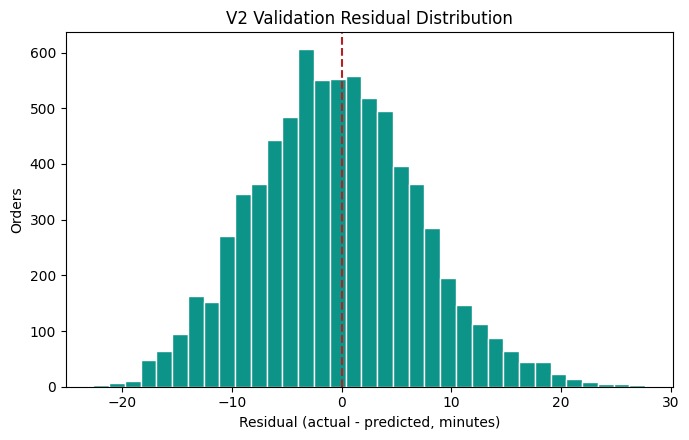

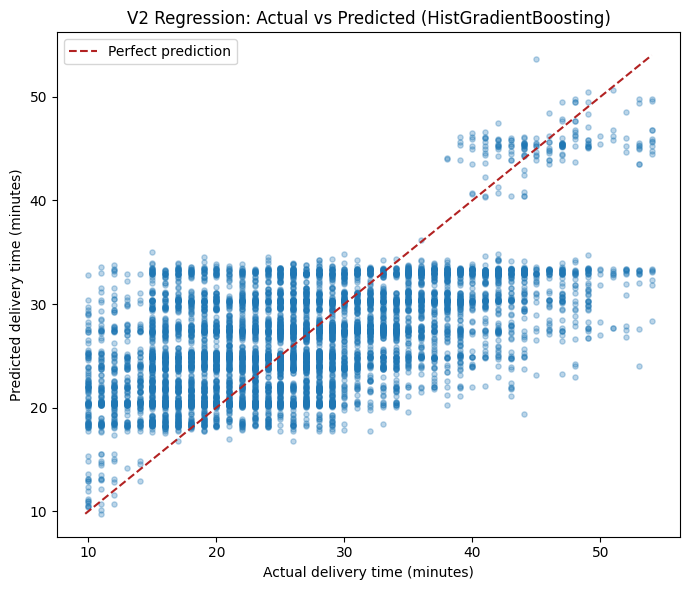

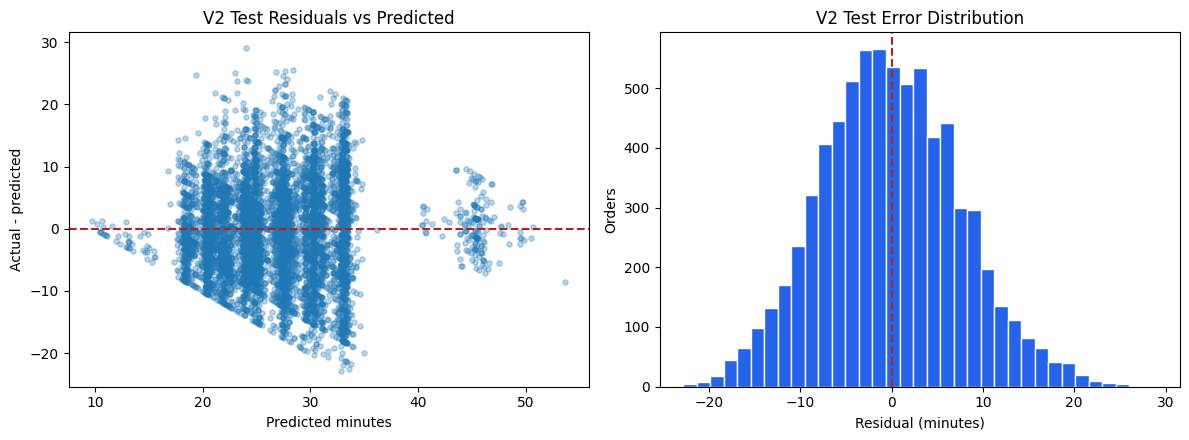

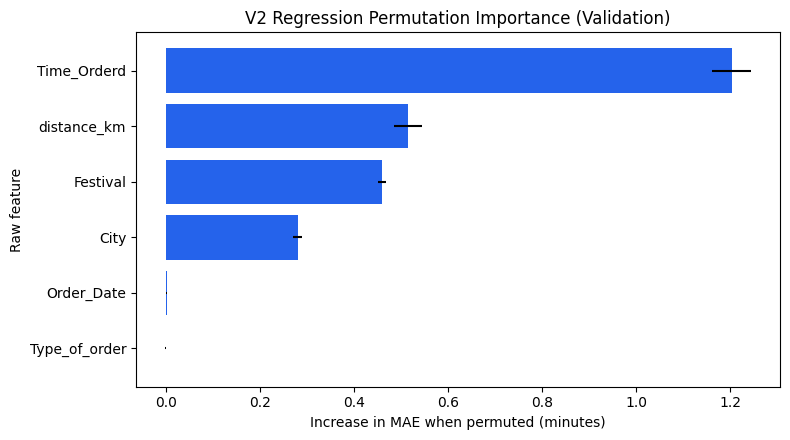

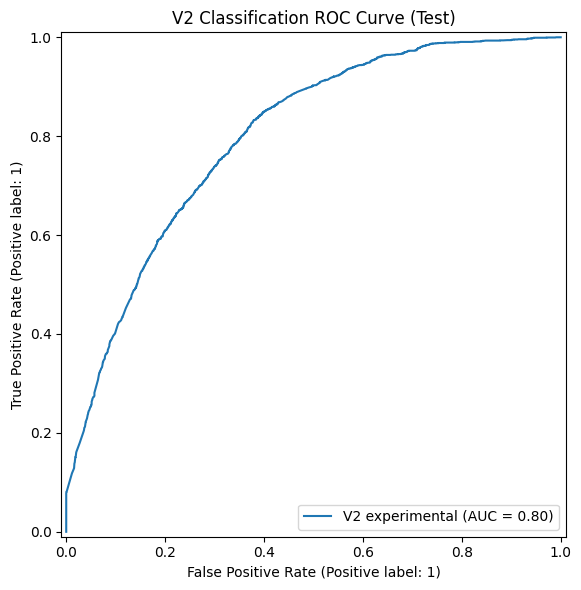

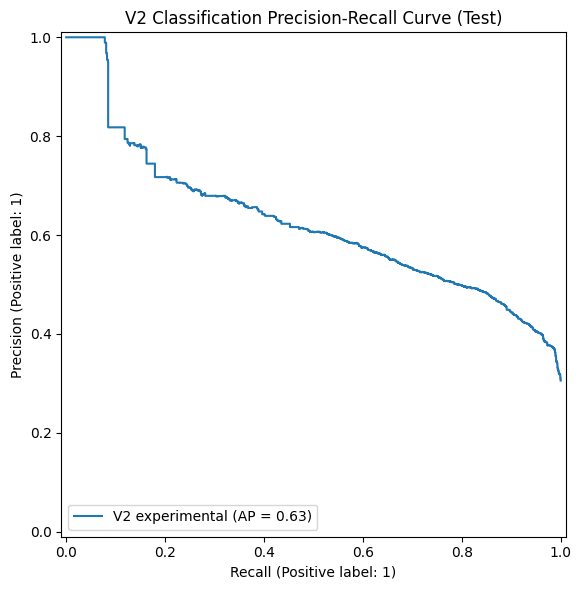

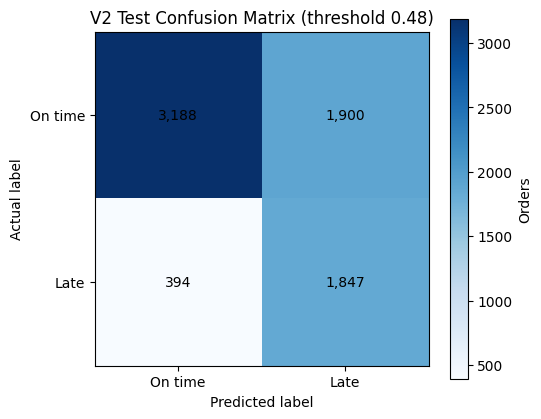

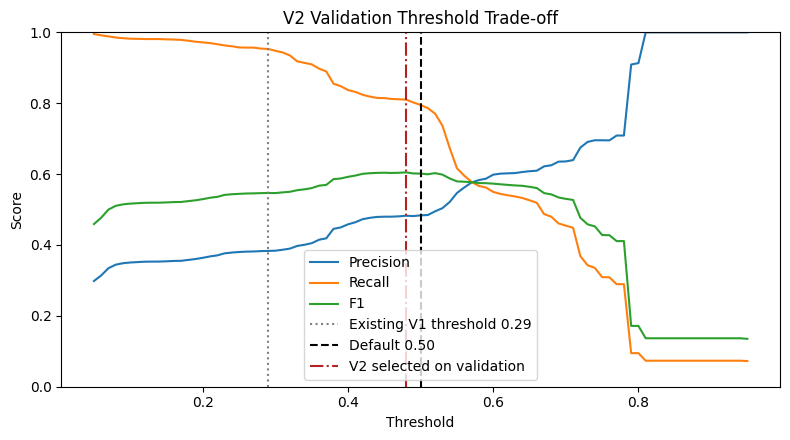

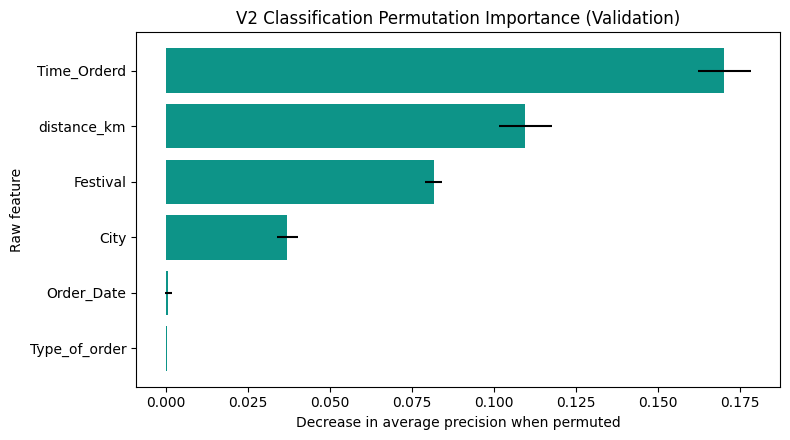

Saved experiment outputs under: C:\Users\javed\Desktop\calibo\Manthan\outputs\model_optimization
Saved experimental pipelines under: C:\Users\javed\Desktop\calibo\Manthan\models\experimental
V2 preference decisions: {'regression': 'V2 experimental', 'classification': 'V2 experimental'}


In [7]:
# Regression validation residual distribution, used only as a diagnostic.
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.hist(best_regression_validation_residuals, bins=35, color="#0D9488", edgecolor="white")
ax.axvline(0, color="firebrick", linestyle="--")
ax.set(title="V2 Validation Residual Distribution",
       xlabel="Residual (actual - predicted, minutes)", ylabel="Orders")
fig.tight_layout()
fig.savefig(REG_PLOT_DIR / "residual_distribution_validation.png", dpi=150)
plt.show()
plt.close(fig)

# Regression diagnostics on the final test period, after all selection is complete.
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(y_reg_test, selected_regression_test_prediction, alpha=0.30, s=14)
limits = [
    min(float(y_reg_test.min()), float(selected_regression_test_prediction.min())),
    max(float(y_reg_test.max()), float(selected_regression_test_prediction.max())),
]
ax.plot(limits, limits, "--", color="firebrick", label="Perfect prediction")
ax.set(title=f"V2 Regression: Actual vs Predicted ({best_regression_name})",
       xlabel="Actual delivery time (minutes)", ylabel="Predicted delivery time (minutes)")
ax.legend()
fig.tight_layout()
fig.savefig(REG_PLOT_DIR / "actual_vs_predicted_test.png", dpi=150)
plt.show()
plt.close(fig)

test_residuals = y_reg_test.to_numpy() - selected_regression_test_prediction
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(selected_regression_test_prediction, test_residuals, alpha=0.30, s=14)
axes[0].axhline(0, color="firebrick", linestyle="--")
axes[0].set(title="V2 Test Residuals vs Predicted",
            xlabel="Predicted minutes", ylabel="Actual - predicted")
axes[1].hist(test_residuals, bins=35, color="#2563EB", edgecolor="white")
axes[1].axvline(0, color="firebrick", linestyle="--")
axes[1].set(title="V2 Test Error Distribution",
            xlabel="Residual (minutes)", ylabel="Orders")
fig.tight_layout()
fig.savefig(REG_PLOT_DIR / "residuals_and_error_distribution_test.png", dpi=150)
plt.show()
plt.close(fig)

reg_permutation = permutation_importance(
    v2_regression_pipeline, X_validation, y_reg_validation,
    scoring="neg_mean_absolute_error", n_repeats=3,
    random_state=RANDOM_STATE, n_jobs=1,
)
reg_importance = pd.DataFrame({
    "feature": FEATURES,
    "importance_mean": reg_permutation.importances_mean,
    "importance_std": reg_permutation.importances_std,
}).sort_values("importance_mean", ascending=False)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(reg_importance.feature[::-1], reg_importance.importance_mean[::-1],
        xerr=reg_importance.importance_std[::-1], color="#2563EB")
ax.set(title="V2 Regression Permutation Importance (Validation)",
       xlabel="Increase in MAE when permuted (minutes)", ylabel="Raw feature")
fig.tight_layout()
fig.savefig(REG_PLOT_DIR / "permutation_importance_validation.png", dpi=150)
reg_importance.to_csv(REG_PLOT_DIR / "permutation_importance_validation.csv", index=False)
plt.show()
plt.close(fig)

# Classification thresholds are selected on validation; these plots use final test predictions.
fig, ax = plt.subplots(figsize=(7, 6))
RocCurveDisplay.from_predictions(
    y_clf_test, selected_classification_test_scores, ax=ax, name="V2 experimental"
)
ax.set_title("V2 Classification ROC Curve (Test)")
fig.tight_layout()
fig.savefig(CLF_PLOT_DIR / "roc_curve_test.png", dpi=150)
plt.show()
plt.close(fig)

fig, ax = plt.subplots(figsize=(7, 6))
PrecisionRecallDisplay.from_predictions(
    y_clf_test, selected_classification_test_scores, ax=ax, name="V2 experimental"
)
ax.set_title("V2 Classification Precision-Recall Curve (Test)")
fig.tight_layout()
fig.savefig(CLF_PLOT_DIR / "precision_recall_curve_test.png", dpi=150)
plt.show()
plt.close(fig)

test_selected_predictions = (
    selected_classification_test_scores >= v2_threshold
).astype("int8")
test_cm = confusion_matrix(y_clf_test, test_selected_predictions, labels=[0, 1])
fig, ax = plt.subplots(figsize=(5.5, 4.5))
image = ax.imshow(test_cm, cmap="Blues")
ax.set(
    title=f"V2 Test Confusion Matrix (threshold {v2_threshold:.2f})",
    xlabel="Predicted label", ylabel="Actual label",
    xticks=[0, 1], yticks=[0, 1],
    xticklabels=["On time", "Late"], yticklabels=["On time", "Late"],
)
for row_index in range(2):
    for column_index in range(2):
        ax.text(column_index, row_index, f"{test_cm[row_index, column_index]:,}",
                ha="center", va="center", color="black")
fig.colorbar(image, ax=ax, label="Orders")
fig.tight_layout()
fig.savefig(CLF_PLOT_DIR / "confusion_matrix_test.png", dpi=150)
plt.show()
plt.close(fig)

fig, ax = plt.subplots(figsize=(8, 4.5))
for metric in ("precision", "recall", "f1"):
    ax.plot(threshold_comparison.threshold, threshold_comparison[metric], label=metric.title())
ax.axvline(0.29, color="gray", linestyle=":", label="Existing V1 threshold 0.29")
ax.axvline(0.50, color="black", linestyle="--", label="Default 0.50")
ax.axvline(v2_threshold, color="firebrick", linestyle="-.", label="V2 selected on validation")
ax.set(title="V2 Validation Threshold Trade-off",
       xlabel="Threshold", ylabel="Score", ylim=(0, 1))
ax.legend()
fig.tight_layout()
fig.savefig(CLF_PLOT_DIR / "threshold_comparison_validation.png", dpi=150)
threshold_comparison.to_csv(OUTPUT_DIR / "classification_threshold_comparison_validation.csv", index=False)
plt.show()
plt.close(fig)

clf_permutation = permutation_importance(
    v2_classification_pipeline, X_validation, y_clf_validation,
    scoring="average_precision", n_repeats=3,
    random_state=RANDOM_STATE, n_jobs=1,
)
clf_importance = pd.DataFrame({
    "feature": FEATURES,
    "importance_mean": clf_permutation.importances_mean,
    "importance_std": clf_permutation.importances_std,
}).sort_values("importance_mean", ascending=False)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(clf_importance.feature[::-1], clf_importance.importance_mean[::-1],
        xerr=clf_importance.importance_std[::-1], color="#0D9488")
ax.set(title="V2 Classification Permutation Importance (Validation)",
       xlabel="Decrease in average precision when permuted", ylabel="Raw feature")
fig.tight_layout()
fig.savefig(CLF_PLOT_DIR / "permutation_importance_validation.png", dpi=150)
clf_importance.to_csv(CLF_PLOT_DIR / "permutation_importance_validation.csv", index=False)
plt.show()
plt.close(fig)

v1_regression_validation_prediction = predict_regression(v1_regression, X_validation)
v1_regression_validation_residuals = y_reg_validation.to_numpy() - v1_regression_validation_prediction
v1_regression_comparison_row = {
    "model": "V1_RandomForestRegressor",
    **{f"train_{key}": value for key, value in v1_reg_train_metrics.items()},
    **{f"validation_{key}": value for key, value in v1_reg_validation_metrics.items()},
    "train_validation_mae_gap": v1_reg_validation_metrics["mae"] - v1_reg_train_metrics["mae"],
    "train_validation_rmse_gap": v1_reg_validation_metrics["rmse"] - v1_reg_train_metrics["rmse"],
    "validation_residual_mean": float(np.mean(v1_regression_validation_residuals)),
    "validation_residual_std": float(np.std(v1_regression_validation_residuals, ddof=1)),
    "validation_residual_p05": float(np.quantile(v1_regression_validation_residuals, 0.05)),
    "validation_residual_median": float(np.median(v1_regression_validation_residuals)),
    "validation_residual_p95": float(np.quantile(v1_regression_validation_residuals, 0.95)),
    "fit_seconds": np.nan,
}
regression_comparison_export = pd.concat(
    [pd.DataFrame([v1_regression_comparison_row]), regression_comparison], ignore_index=True
)

v1_classification_comparison_row = {
    "model": "V1_RandomForestClassifier",
    "train_roc_auc": v1_clf_train_metrics["roc_auc"],
    "validation_roc_auc": v1_clf_validation_metrics["roc_auc"],
    "train_pr_auc": v1_clf_train_metrics["pr_auc"],
    "validation_pr_auc": v1_clf_validation_metrics["pr_auc"],
    "train_validation_roc_auc_gap": v1_clf_train_metrics["roc_auc"] - v1_clf_validation_metrics["roc_auc"],
    "train_validation_pr_auc_gap": v1_clf_train_metrics["pr_auc"] - v1_clf_validation_metrics["pr_auc"],
    "fit_seconds": np.nan,
}
for threshold in (0.29, 0.50):
    for split, labels, scores in (
        ("train", y_clf_train, v1_clf_train_scores),
        ("validation", y_clf_validation, v1_clf_validation_scores),
    ):
        metrics = classification_metrics(labels, scores, threshold)
        for metric in ("precision", "recall", "f1", "accuracy", "balanced_accuracy"):
            v1_classification_comparison_row[f"{split}_{metric}_at_{threshold:.2f}"] = metrics[metric]
        v1_classification_comparison_row[f"{split}_confusion_matrix_at_{threshold:.2f}"] = json.dumps(
            metrics["confusion_matrix"], separators=(",", ":")
        )
classification_comparison_export = pd.concat(
    [pd.DataFrame([v1_classification_comparison_row]), classification_comparison],
    ignore_index=True,
)

regression_comparison_export.to_csv(OUTPUT_DIR / "regression_comparison.csv", index=False)
classification_comparison_export.to_csv(OUTPUT_DIR / "classification_comparison.csv", index=False)
threshold_comparison.to_csv(OUTPUT_DIR / "classification_threshold_comparison_validation.csv", index=False)
joblib.dump(v2_regression_pipeline, EXPERIMENT_MODEL_DIR / "regression_optimized_v2.joblib")
joblib.dump(v2_classification_pipeline, EXPERIMENT_MODEL_DIR / "classification_optimized_v2.joblib")
(EXPERIMENT_MODEL_DIR / "classification_threshold_v2.json").write_text(
    json.dumps({
        "threshold": v2_threshold,
        "selected_using": "V2 validation data only",
        "rule": "Maximum validation F1; ties prefer the higher threshold.",
        "interpretation": "Estimated late-delivery risk score; not a calibrated probability.",
        "sla_minutes": SLA_MINUTES,
    }, indent=2),
    encoding="utf-8",
)

summary = {
    "experiment": "Manthan Model Optimization V2",
    "diagnostic_only_for_v1": False,
    "random_state": RANDOM_STATE,
    "sla_minutes": SLA_MINUTES,
    "sla_is_official_promise": False,
    "features": FEATURES,
    "targets": {"regression": REG_TARGET, "classification": CLF_TARGET},
    "split": split_table.to_dict(orient="records"),
    "preprocessing_fit_partition": "train only",
    "distance_availability_assumption": (
        "distance_km assumes selected-store and customer coordinates are available before prediction; "
        "verify this operational timing before deployment."
    ),
    "excluded_fields": [
        "IDs", "delivery_time from classification inputs", "is_late from regression inputs",
        "Time_Order_picked", "rider fields", "vehicle fields", "weather", "traffic",
        "post-order or target-derived fields",
    ],
    "selection_rules": {
        "regression": "Lowest validation MAE; V2 preferred only if validation MAE improves and the train-validation MAE gap narrows.",
        "classification": "Highest validation PR-AUC; V2 preferred only if validation PR-AUC improves and the absolute train-validation PR-AUC gap narrows.",
        "threshold": "V2 maximum validation F1 over 0.05..0.95 by 0.01; ties prefer the higher threshold. Not cost-optimal.",
    },
    "v1_validation": {
        "regression": {
            "train": v1_reg_train_metrics,
            "validation": v1_reg_validation_metrics,
            "mae_gap": v1_reg_gap,
        },
        "classification": {
            "train_roc_auc": v1_clf_train_metrics["roc_auc"],
            "validation_roc_auc": v1_clf_validation_metrics["roc_auc"],
            "train_pr_auc": v1_clf_train_metrics["pr_auc"],
            "validation_pr_auc": v1_clf_validation_metrics["pr_auc"],
            "threshold_0.29_validation": classification_metrics(
                y_clf_validation, v1_clf_validation_scores, 0.29
            ),
            "threshold_0.50_validation": v1_clf_validation_metrics,
            "pr_auc_gap": v1_clf_gap,
        },
    },
    "v2_selected": {
        "regression_model": best_regression_name,
        "regression_train": {
            key: float(best_reg_row[f"train_{key}"]) for key in ("mae", "rmse", "r2")
        },
        "regression_validation": best_regression_validation_metrics,
        "regression_mae_gap": v2_reg_gap,
        "regression_validation_improved_vs_v1": bool(regression_validation_improved),
        "regression_gap_reduced_vs_v1": bool(regression_gap_reduced),
        "prefer_v2_regression": bool(prefer_v2_regression),
        "classification_model": best_classification_name,
        "classification_train_roc_auc": float(best_clf_row["train_roc_auc"]),
        "classification_validation_roc_auc": float(best_clf_row["validation_roc_auc"]),
        "classification_train_pr_auc": float(best_clf_row["train_pr_auc"]),
        "classification_validation_pr_auc": float(best_clf_row["validation_pr_auc"]),
        "classification_pr_auc_gap": v2_clf_gap,
        "classification_validation_improved_vs_v1": bool(classification_validation_improved),
        "classification_gap_reduced_vs_v1": bool(classification_gap_reduced),
        "prefer_v2_classification": bool(prefer_v2_classification),
        "threshold": v2_threshold,
        "validation_threshold_metrics": v2_validation_threshold_metrics,
        "scores_are_calibrated_probabilities": False,
    },
    "test_evaluation_after_selection_only": test_evaluations,
    "hypotheses_not_proven": [
        "Constrained capacity may reduce train-specific fitting.",
        "Unobserved operational inputs and food-delivery versus quick-commerce differences may limit performance.",
        "distance_km timing and missingness may affect operational usefulness.",
    ],
    "preferred_models": {
        "regression": "V2 experimental" if prefer_v2_regression else "V1 existing",
        "classification": "V2 experimental" if prefer_v2_classification else "V1 existing",
    },
}
(OUTPUT_DIR / "optimization_summary.json").write_text(
    json.dumps(summary, indent=2, allow_nan=False), encoding="utf-8"
)

print("Saved experiment outputs under:", OUTPUT_DIR)
print("Saved experimental pipelines under:", EXPERIMENT_MODEL_DIR)
print("V2 preference decisions:", summary["preferred_models"])

## 9. Final generalization analysis and recommendations

### How to read the outcome

- **Why V1 overfit:** the observed train-validation gaps are the evidence. High model capacity is a plausible explanation, not a proven cause.
- **Experiments:** the notebook compares 18 constrained Random Forest settings per task, Ridge, Logistic Regression, and histogram gradient boosting.
- **Best models and measured results:** the final executed cell prints the selected validation models, train/validation/test metrics, and gap comparisons from this run.
- **Overfitting and underfitting:** a reduced gap supports improved generalization only when validation performance also improves. If both validation and test improve while train and validation scores are close, there is no evidence that the constraints caused harmful underfitting; remaining unexplained variation is still a limitation.
- **Retention decision:** the V2 preference rule requires better primary validation performance and a smaller absolute train-validation gap. If a task does not meet both conditions, V1 remains preferred for that task. V1 dashboard artifacts remain untouched either way.
- **Future work:** validate on actual quick-commerce orders; verify that store/customer coordinates and `distance_km` are available at prediction time; collect operational features only with verified pre-prediction timestamps; and define threshold costs with stakeholders before claiming a cost-optimal operating point.

These are measured comparisons, not causal findings. Explanations involving missing operational variables, distance timing, or dataset mismatch remain hypotheses. Neither model produces a calibrated probability: this notebook does not perform probability calibration.

In [8]:
print("FINAL EXPERIMENT SUMMARY")
print("\nWhy V1 appeared to overfit (observed evidence vs hypothesis):")
print(f"  Observed regression MAE gap: {v1_reg_gap:.3f} minutes; classifier PR-AUC gap: {v1_clf_gap:.4f}.")
print("  Hypothesis: the unconstrained V1 forests learned training-specific patterns; the gaps alone do not prove the cause.")
print("\nExperiments: 18 constrained forest settings per task, Ridge, Logistic Regression, and sklearn histogram gradient boosting.")
print("Regression: selected", best_regression_name)
print(f"  V1 train/validation/test MAE: {v1_reg_train_metrics['mae']:.3f} / "
      f"{v1_reg_validation_metrics['mae']:.3f} / {test_evaluations['V1']['regression']['mae']:.3f}")
print(f"  V2 train/validation/test MAE: {best_reg_row['train_mae']:.3f} / "
      f"{best_regression_validation_metrics['mae']:.3f} / "
      f"{test_evaluations['V2_experimental']['regression']['mae']:.3f}")
print(f"  V1 validation MAE={v1_reg_validation_metrics['mae']:.3f}; "
      f"V2 validation MAE={best_regression_validation_metrics['mae']:.3f}")
print(f"  V1 MAE gap={v1_reg_gap:.3f}; V2 MAE gap={v2_reg_gap:.3f}")
print("  Validation MAE improved:", regression_validation_improved,
      "| absolute train-validation gap reduced:", regression_gap_reduced)
print("  Preferred:", summary["preferred_models"]["regression"])
print("Classification: selected", best_classification_name)
print(f"  V1 train/validation/test PR-AUC: {v1_clf_train_metrics['pr_auc']:.4f} / "
      f"{v1_clf_validation_metrics['pr_auc']:.4f} / "
      f"{test_evaluations['V1']['classification_at_0.29']['pr_auc']:.4f}")
print(f"  V2 train/validation/test PR-AUC: {best_clf_row['train_pr_auc']:.4f} / "
      f"{best_clf_row['validation_pr_auc']:.4f} / "
      f"{test_evaluations['V2_experimental']['classification_at_selected_threshold']['pr_auc']:.4f}")
print(f"  V1 train/validation ROC-AUC: {v1_clf_train_metrics['roc_auc']:.4f} / "
      f"{v1_clf_validation_metrics['roc_auc']:.4f}; V2: "
      f"{best_clf_row['train_roc_auc']:.4f} / {best_clf_row['validation_roc_auc']:.4f}")
print(f"  V1 validation PR-AUC={v1_clf_validation_metrics['pr_auc']:.4f}; "
      f"V2 validation PR-AUC={best_clf_row['validation_pr_auc']:.4f}")
print(f"  V1 PR-AUC gap={v1_clf_gap:.4f}; V2 PR-AUC gap={v2_clf_gap:.4f}")
print("  Validation PR-AUC improved:", classification_validation_improved,
      "| absolute train-validation gap reduced:", classification_gap_reduced)
print(f"  V2 validation threshold={v2_threshold:.2f}; not cost-optimal or calibrated")
print("  Test V2 threshold metrics (final evaluation only):",
      {key: test_evaluations['V2_experimental']['classification_at_selected_threshold'][key]
       for key in ('precision', 'recall', 'f1', 'accuracy', 'balanced_accuracy')})
print("  Preferred:", summary["preferred_models"]["classification"])
print("\nRecommendation: retain the V2 experimental models for further offline validation; do not replace V1 dashboard artifacts.")
print("Limitations: food-delivery data is a quick-commerce proxy; verify distance_km timing; weather/traffic availability was not verified; risk scores are not calibrated probabilities.")

required_outputs = [
    OUTPUT_DIR / "regression_comparison.csv",
    OUTPUT_DIR / "classification_comparison.csv",
    OUTPUT_DIR / "classification_threshold_comparison_validation.csv",
    OUTPUT_DIR / "optimization_summary.json",
    REG_PLOT_DIR / "actual_vs_predicted_test.png",
    REG_PLOT_DIR / "residual_distribution_validation.png",
    REG_PLOT_DIR / "residuals_and_error_distribution_test.png",
    REG_PLOT_DIR / "permutation_importance_validation.png",
    CLF_PLOT_DIR / "roc_curve_test.png",
    CLF_PLOT_DIR / "precision_recall_curve_test.png",
    CLF_PLOT_DIR / "confusion_matrix_test.png",
    CLF_PLOT_DIR / "threshold_comparison_validation.png",
    CLF_PLOT_DIR / "permutation_importance_validation.png",
    EXPERIMENT_MODEL_DIR / "regression_optimized_v2.joblib",
    EXPERIMENT_MODEL_DIR / "classification_optimized_v2.joblib",
    EXPERIMENT_MODEL_DIR / "classification_threshold_v2.json",
]
missing_outputs = [str(path) for path in required_outputs if not path.is_file()]
if missing_outputs:
    raise FileNotFoundError(f"Expected experiment outputs were not created: {missing_outputs}")

# Reopen the experimental artifacts and prove both saved pipelines accept approved input rows.
reloaded_regression = joblib.load(EXPERIMENT_MODEL_DIR / "regression_optimized_v2.joblib")
reloaded_classification = joblib.load(EXPERIMENT_MODEL_DIR / "classification_optimized_v2.joblib")
sample = X_test.head(5)
assert np.isfinite(reloaded_regression.predict(sample)).all()
assert reloaded_classification.predict_proba(sample).shape == (len(sample), 2)
print(f"Output validation passed ({len(required_outputs)} required files).")
print("Experimental model reload and sample predictions passed.")
print("V1 model files, existing notebooks, outputs/ml metrics, and dashboard were not written.")

FINAL EXPERIMENT SUMMARY

Why V1 appeared to overfit (observed evidence vs hypothesis):
  Observed regression MAE gap: 2.942 minutes; classifier PR-AUC gap: 0.4128.
  Hypothesis: the unconstrained V1 forests learned training-specific patterns; the gaps alone do not prove the cause.

Experiments: 18 constrained forest settings per task, Ridge, Logistic Regression, and sklearn histogram gradient boosting.
Regression: selected HistGradientBoosting
  V1 train/validation/test MAE: 3.310 / 6.252 / 6.272
  V2 train/validation/test MAE: 6.012 / 5.985 / 6.129
  V1 validation MAE=6.252; V2 validation MAE=5.985
  V1 MAE gap=2.942; V2 MAE gap=0.027
  Validation MAE improved: True | absolute train-validation gap reduced: True
  Preferred: V2 experimental
Classification: selected HistGradientBoosting_balanced
  V1 train/validation/test PR-AUC: 0.9945 / 0.5817 / 0.5995
  V2 train/validation/test PR-AUC: 0.6352 / 0.6227 / 0.6266
  V1 train/validation ROC-AUC: 0.9977 / 0.7786; V2: 0.8102 / 0.8081
  V1 

Output validation passed (16 required files).
Experimental model reload and sample predictions passed.
V1 model files, existing notebooks, outputs/ml metrics, and dashboard were not written.
